# Лекция 1. Введение в компьютерное зрение
## Демонстрация и самостоятельная практика

**Часть 1** — демонстрации материалов лекции.  
**Часть 2** — короткие самостоятельные шаги. В каждом месте `# YOUR CODE HERE` нужно дописать **1–2 строки**.

## Часть 1. Демонстрация преподавателя

Используем встроенный датасет рукописных цифр. Здесь уже знакомая задача классификации, только объектом становится изображение.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['image.cmap'] = 'gray'

### 1. Изображения и классы
Каждое изображение — рукописная цифра от 0 до 9. Пока не разбираем подробно устройство массива: это тема следующего занятия.

In [3]:
digits = load_digits()
images = digits.images
labels = digits.target

print('Количество изображений:', len(images))
print('Размер изображения:', images[0].shape)
print('Число значений в изображении 8×8:', images[0].size)
print('Число классов:', len(np.unique(labels)))

Количество изображений: 1797
Размер изображения: (8, 8)
Число значений в изображении 8×8: 64
Число классов: 10


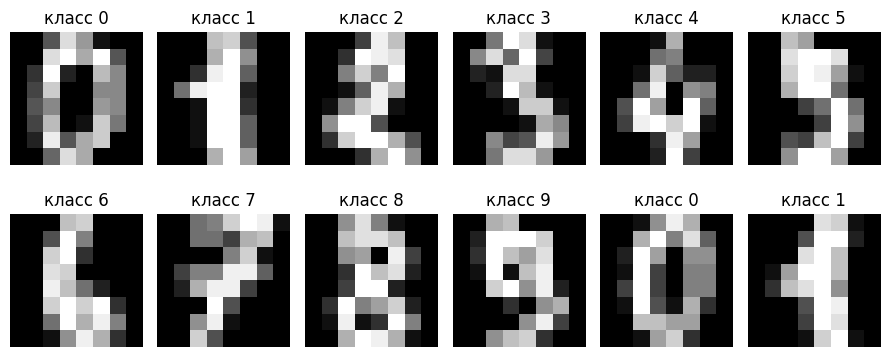

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(9, 4))
for ax, image, label in zip(axes.ravel(), images[:12], labels[:12]):
    ax.imshow(image)
    ax.set_title(f'класс {label}')
    ax.axis('off')
plt.tight_layout()
plt.show()

### 2. Превращаем картинку в знакомые признаки
Для первого эксперимента просто вытянем 8×8 = 64 значения в одну строку. Это **не лучший способ компьютерного зрения**, а мостик к уже знакомому классическому ML.

In [5]:
X = images.reshape(len(images), -1)
y = labels

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)

X_train: (1347, 64)
X_test : (450, 64)


In [7]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(f'Accuracy: {accuracy_score(y_test, pred):.3f}')

Accuracy: 0.984


### 3. Одного числа недостаточно
Accuracy полезна, но не показывает, **какие именно** ошибки делает модель.

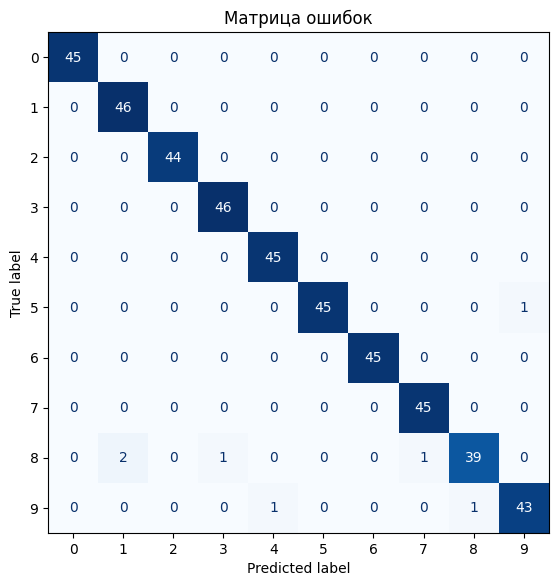

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Матрица ошибок')
plt.show()

### 4. Смотрим на ошибки глазами
Иногда одна ошибочная картинка рассказывает о модели больше, чем ещё одна цифра после запятой в метрике.

Ошибок на тесте: 7


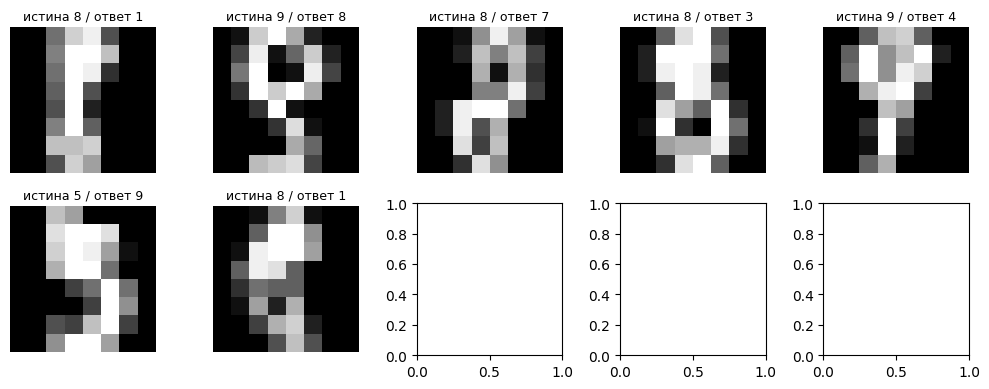

In [9]:
wrong = np.where(pred != y_test)[0]
print('Ошибок на тесте:', len(wrong))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.ravel(), wrong[:10]):
    ax.imshow(X_test[idx].reshape(8, 8))
    ax.set_title(f'истина {y_test[idx]} / ответ {pred[idx]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 5. Ложная корреляция: модель может пользоваться подсказкой
Возьмём только цифры 3 и 8. Для 3 поставим светлый маркер слева сверху, для 8 — справа сверху. Маркер очень удобен модели, но **не является формой цифры**.

In [10]:
mask = np.isin(labels, [3, 8])
X_bin = images[mask]
y_bin = labels[mask]

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_bin, y_bin, test_size=0.30, random_state=42, stratify=y_bin
)

def add_marker(imgs, ys, flip=False):
    result = imgs.copy()
    for img, label in zip(result, ys):
        left = (label == 3)
        if flip:
            left = not left
        if left:
            img[0:2, 0:2] = 16
        else:
            img[0:2, -2:] = 16
    return result

train_marked = add_marker(Xb_train, yb_train)
test_same = add_marker(Xb_test, yb_test)
test_flipped = add_marker(Xb_test, yb_test, flip=True)

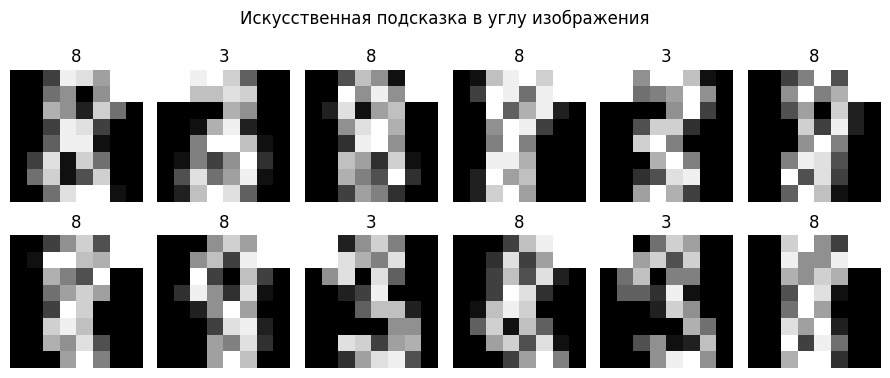

In [11]:
fig, axes = plt.subplots(2, 6, figsize=(9, 4))
for ax, image, label in zip(axes.ravel(), train_marked[:12], yb_train[:12]):
    ax.imshow(image, vmin=0, vmax=16)
    ax.set_title(str(label))
    ax.axis('off')
plt.suptitle('Искусственная подсказка в углу изображения')
plt.tight_layout()
plt.show()

In [12]:
cheating_model = model = KNeighborsClassifier(n_neighbors=5)
cheating_model.fit(train_marked.reshape(len(train_marked), -1), yb_train)

pred_same = cheating_model.predict(test_same.reshape(len(test_same), -1))
pred_flipped = cheating_model.predict(test_flipped.reshape(len(test_flipped), -1))

print('Тест с привычной подсказкой:', accuracy_score(yb_test, pred_same))
print('Тест с перевёрнутой подсказкой:', accuracy_score(yb_test, pred_flipped))

Тест с привычной подсказкой: 1.0
Тест с перевёрнутой подсказкой: 0.0


**Обсуждение:** если качество резко падает после изменения несущественной подсказки, модель училась не той закономерности, которую мы от неё ожидали.

---
## Часть 2. Самостоятельные мини-задачи

Каждый шаг — 1–2 строки. Задания независимы друг от друга настолько, насколько возможно; после каждого есть ориентир для самопроверки.

### Задание 1. Сколько классов?
Получите количество различных меток в `labels`.

**Самопроверка:** должно получиться `10`.

In [ ]:
# YOUR CODE HERE (1 строка)
# n_classes = ...

### Задание 2. Сколько чисел в одной картинке?
Получите количество значений в `images[0]`.

**Самопроверка:** `64`.

In [ ]:
# YOUR CODE HERE (1 строка)
# n_values = ...

### Задание 3. Оставьте только цифры 1 и 7
Создайте булеву маску `mask_17`.

In [ ]:
# YOUR CODE HERE (1 строка)
# mask_17 = ...

### Задание 4. Посмотрите на одну картинку
Покажите `images[25]` и напечатайте её правильную метку.

In [ ]:
idx = 25
# YOUR CODE HERE (2 строки)
# plt.imshow(...)
# print(...)

### Задание 5. Разделите выборку
Разделите `X` и `y`: test — 25%, `random_state=1`, со `stratify=y`.

In [ ]:
# YOUR CODE HERE (1 строка)
# X_train_s, X_test_s, y_train_s, y_test_s = ...

### Задание 6. Обучите знакомую модель
Создайте `KNeighborsClassifier` и обучите её на данных из задания 5.

In [ ]:
# YOUR CODE HERE (2 строки)
# model_s = ...
# model_s.fit(...)

### Задание 7. Получите ответы и accuracy
Сделайте предсказания на `X_test_s` и посчитайте accuracy.

In [ ]:
# YOUR CODE HERE (2 строки)
# pred_s = ...
# score_s = ...

### Задание 8. Найдите ошибки
Получите индексы тестовых объектов, где ответ модели не совпал с правильной меткой.

In [ ]:
# YOUR CODE HERE (1 строка)
# wrong_s = ...

### Задание 9. Сломайте ложную подсказку
Используйте уже готовую функцию `add_marker`: создайте тест с перевёрнутым правилом и получите ответы `cheating_model`.

In [ ]:
# YOUR CODE HERE (2 строки)
# broken_test = ...
# broken_pred = ...

### Вопрос для обсуждения
Модель показывает 99% accuracy. Какой **один** новый эксперимент вы бы сделали, чтобы проверить, что она распознаёт сам объект, а не фон, рамку, водяной знак или условия съёмки?